# Phase 2.1 — Probability Forecasting Baselines

**Models:** Constant Probability and L2 Logistic Regression.  
**Market:** SPY · Daily · **Horizon:** next-open to following-open (one holding session).

**Protocol:** `2005–2018` training with internal purged walk-forward CV; `2019–2021` validation; `2022–2026` final test untouched.

This notebook **visualizes outputs** from the reproducible script. Execute from the project root first:

```bash
python -m quant_trading.pipeline  # only if Phase 1 has not run
python -m quant_trading.phase2_baselines
```

No backtest or trading profitability claims are made in Phase 2.1.

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibrationDisplay

current_dir = Path.cwd().resolve()
for PROJECT_ROOT in (current_dir, *current_dir.parents):
    if (PROJECT_ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT_DIR = PROJECT_ROOT / "reports" / "phase2_1"
assert REPORT_DIR.is_dir(), "Run python -m quant_trading.phase2_baselines first."

## 1. Research setup and candidate selection

**Baseline:** Training-fold prior $\hat p=\bar y_{train}$.  
**Logistic:** $p_t=\sigma(\beta_0+\beta^\top X_t)$ with L2 regularization.  
`C` is chosen using training-only cross-validation based on minimum mean **log loss**. The feature scaler is fitted separately inside each training fold.

In [2]:
config = json.loads((REPORT_DIR / "config.json").read_text())
print("Chosen C:", config["chosen_C"])
print("Training period:", config["train_dates"])
print("Validation period:", config["validation_dates"])
print("Final test read:", config["test_used"])

cv_summary = pd.read_csv(REPORT_DIR / "cv_summary.csv")
cv_folds = pd.read_csv(REPORT_DIR / "cv_folds.csv")
display(cv_summary.sort_values("cv_log_loss"))

Chosen C: 0.01
Training period: ['2005-04-05', '2018-12-27']
Validation period: ['2019-01-02', '2021-12-29']
Final test read: False


,model,C,cv_log_loss,cv_log_loss_std,cv_brier_score,cv_roc_auc
1,Logistic Regression,0.01,0.686492,0.012788,0.246682,0.490640
2,Logistic Regression,0.10,0.686665,0.013080,0.246767,0.493508
3,Logistic Regression,1.00,0.686802,0.012996,0.246835,0.493335
0,Constant Probability,NaN,0.687504,0.008963,0.247182,0.500000


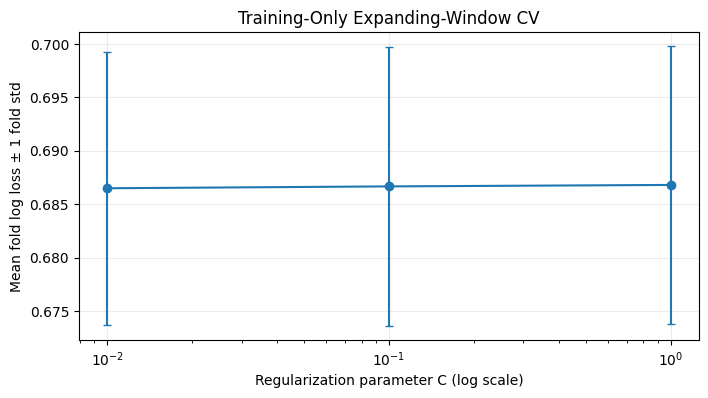

In [3]:
logistic_cv = cv_summary.loc[cv_summary["model"] == "Logistic Regression"].sort_values("C")
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(logistic_cv["C"], logistic_cv["cv_log_loss"],
            yerr=logistic_cv["cv_log_loss_std"], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("Regularization parameter C (log scale)")
ax.set_ylabel("Mean fold log loss ± 1 fold std")
ax.set_title("Training-Only Expanding-Window CV")
ax.grid(alpha=0.25)
plt.show()

## 2. Validation performance (2019–2021)

**Lower is better** for Log Loss and Brier Score; **higher is better** for ROC-AUC. No model has been selected using 2022–2026 data.

In [4]:
metrics = pd.read_csv(REPORT_DIR / "validation_metrics.csv")
pred = pd.read_csv(REPORT_DIR / "validation_predictions.csv", parse_dates=["signal_date"])
pred = pred.set_index("signal_date")
display(metrics)
display(pred.head())
assert pred.index.is_monotonic_increasing
assert set(pred["actual_label"].unique()).issubset({0, 1})

,model,log_loss,brier_score,roc_auc,observed_positive_rate,mean_predicted_probability
0,Constant Probability,0.679269,0.243076,0.50000,0.6,0.544534
1,Logistic Regression,0.687180,0.246934,0.48693,0.6,0.538449


,actual_label,p_baseline,p_logistic
signal_date,,,
2019-01-02,0,0.544534,0.514473
2019-01-03,1,0.544534,0.522948
2019-01-04,1,0.544534,0.522789
2019-01-07,1,0.544534,0.452749
2019-01-08,0,0.544534,0.479112


## 3. Probability calibration

Reliability diagrams compare average predicted probability against observed event frequency. They do not prove that a trading strategy is profitable. The constant-probability baseline may occupy only one bin.

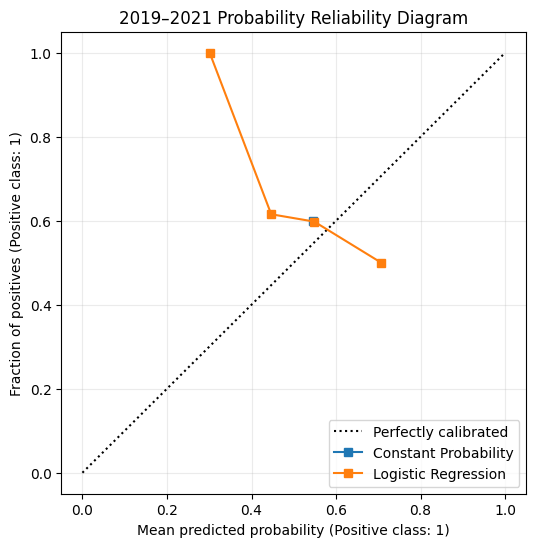

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
for label, col in [("Constant Probability", "p_baseline"), ("Logistic Regression", "p_logistic")]:
    CalibrationDisplay.from_predictions(
        pred["actual_label"], pred[col], n_bins=6,
        strategy="uniform", name=label, ax=ax
    )
ax.set_title("2019–2021 Probability Reliability Diagram")
ax.grid(alpha=0.25)
plt.show()

## 4. Logistic coefficients

Coefficients are in **standardized feature units**. Their magnitudes are not necessarily causal effects and are sensitive to feature correlation.

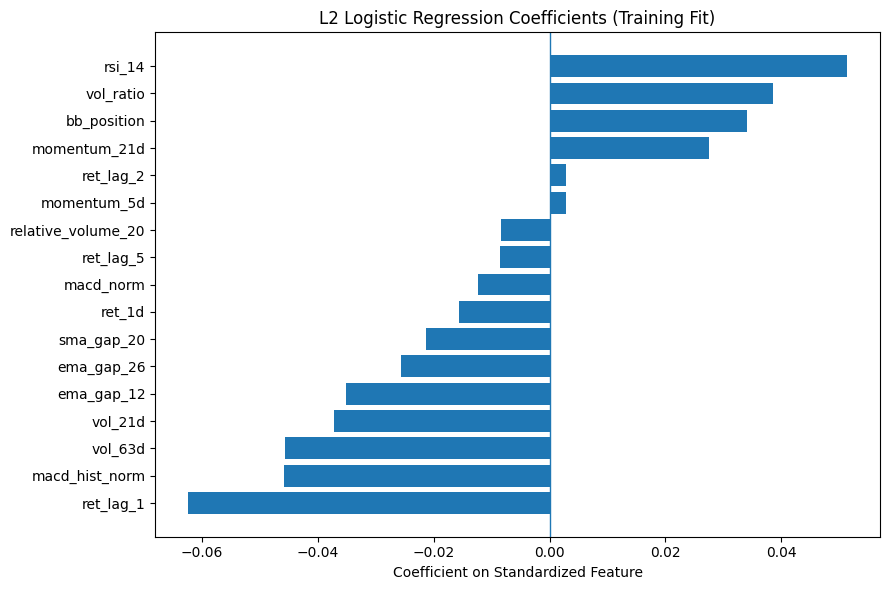

In [6]:
coef = pd.read_csv(REPORT_DIR / "logistic_coefficients.csv")
fig, ax = plt.subplots(figsize=(9, 6))
coef_plot = coef.sort_values("coefficient_scaled")
ax.barh(coef_plot["feature"], coef_plot["coefficient_scaled"])
ax.axvline(0, linewidth=1)
ax.set_title("L2 Logistic Regression Coefficients (Training Fit)")
ax.set_xlabel("Coefficient on Standardized Feature")
plt.tight_layout()
plt.show()

## Does logistic regression improve on the training prior?

The best logistic configuration was $C=0.01$. Mean training-era walk-forward Log Loss was 0.68649, slightly below the prior’s 0.68750. The ranking reversed on the 755 development observations. Logistic regression scored 0.68718 versus 0.67927 for the prior, with Brier scores of 0.24693 versus 0.24308 and AUCs of 0.48693 versus 0.50000.

The prior assigns 54.45% to every day. Logistic regression predicts 53.84% on average. Both underestimate the observed 60.00% (453 positive labels), and varying the daily probabilities worsened the logistic model’s aggregate score on this period. The sign of a standardized coefficient describes a conditional association in the fitted model. Correlated indicators limit its interpretation.